In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from pathlib import Path

In [2]:
uploaded = files.upload()
arquivo = next(iter(uploaded))

Saving LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoTRANSFORMED.csv to LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoTRANSFORMED.csv


In [3]:
dados_brutos = pd.read_csv(arquivo, header=None)

print("Dimensões do arquivo:", dados_brutos.shape)
dados_brutos.head()

Dimensões do arquivo: (122, 17)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,NaN,NaN,NaN,trabecular_BMD_mg_per_cubic_centimeters,trabecular_BMD_mg_per_cubic_centimeters,trabecular_BMD_mg_per_cubic_centimeters,trabecular_BMD_mg_per_cubic_centimeters,trabecular_BMD_change_from_baseline_percent,trabecular_BMD_change_from_baseline_percent,trabecular_BMD_change_from_baseline_percent,cortical_BMD_mg_per_cubic_centimeters,cortical_BMD_mg_per_cubic_centimeters,cortical_BMD_mg_per_cubic_centimeters,cortical_BMD_mg_per_cubic_centimeters,cortical_BMD_change_from_baseline_percent,cortical_BMD_change_from_baseline_percent,cortical_BMD_change_from_baseline_percent
1,Source Name,PWB,Duration,0 week,1 week,2 week,4 week,1 week,2 week,4 week,0 week,1 week,2 week,4 week,1 week,2 week,4 week
2,475796,PWB100,4wk,181.7,165.6,162.6,168.7,-8.9,-10.5,-7.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,475803,PWB100,4wk,202.5,185.4,173.7,181.6,-8.4,-14.2,-10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,479659,PWB100,1wk,133.6,139.1,NaN,NaN,4.1,NaN,NaN,1270.3,1282.3,NaN,NaN,0.9,NaN,NaN


In [4]:
colunas = [
    "animal_id", "PWB", "duracao",
    "trab_BMD_0", "trab_BMD_1", "trab_BMD_2", "trab_BMD_4",
    "trab_change_1", "trab_change_2", "trab_change_4",
    "cort_BMD_0", "cort_BMD_1", "cort_BMD_2", "cort_BMD_4",
    "cort_change_1", "cort_change_2", "cort_change_4"
]

df = dados_brutos.iloc[2:].copy()
df.columns = colunas
df = df.reset_index(drop=True)


for coluna in colunas[3:]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df["animal_id"] = pd.to_numeric(df["animal_id"], errors="coerce")
df["PWB"] = df["PWB"].str.strip()
df["duracao"] = df["duracao"].str.strip()

print("Número de animais:", len(df))
df.head()

Número de animais: 120


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_1,trab_BMD_2,trab_BMD_4,trab_change_1,trab_change_2,trab_change_4,cort_BMD_0,cort_BMD_1,cort_BMD_2,cort_BMD_4,cort_change_1,cort_change_2,cort_change_4
0,475796,PWB100,4wk,181.7,165.6,162.6,168.7,-8.9,-10.5,-7.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,475803,PWB100,4wk,202.5,185.4,173.7,181.6,-8.4,-14.2,-10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,479659,PWB100,1wk,133.6,139.1,NaN,NaN,4.1,NaN,NaN,1270.3,1282.3,NaN,NaN,0.9,NaN,NaN
3,479660,PWB100,2wk,122.8,108.7,100.9,NaN,-14.5,-23.1,NaN,1303.5,1312.5,1327.3,NaN,0.7,1.8,NaN
4,479661,PWB20,2wk,141.8,127.0,113.1,NaN,-10.4,-20.2,NaN,1306.8,1321.4,1319.8,NaN,1.1,1.0,NaN


In [5]:
print("Dimensões:", df.shape)
print("\nTipos de dados:")
print(df.dtypes)

print("\nQuantidade de animais por grupo:")
print(df["PWB"].value_counts().sort_index())

print("\nQuantidade por grupo e duração:")
display(pd.crosstab(df["PWB"], df["duracao"]))

print("\nIDs duplicados:", df["animal_id"].duplicated().sum())

Dimensões: (120, 17)

Tipos de dados:
animal_id          int64
PWB               object
duracao           object
trab_BMD_0       float64
trab_BMD_1       float64
trab_BMD_2       float64
trab_BMD_4       float64
trab_change_1    float64
trab_change_2    float64
trab_change_4    float64
cort_BMD_0       float64
cort_BMD_1       float64
cort_BMD_2       float64
cort_BMD_4       float64
cort_change_1    float64
cort_change_2    float64
cort_change_4    float64
dtype: object

Quantidade de animais por grupo:
PWB
PWB100    30
PWB20     28
PWB40     30
PWB70     32
Name: count, dtype: int64

Quantidade por grupo e duração:


duracao,1wk,2wk,4wk
PWB,,,
PWB100,7,10,13
PWB20,6,12,10
PWB40,6,12,12
PWB70,10,11,11



IDs duplicados: 0


In [6]:
ausentes = pd.DataFrame({
    "quantidade_ausente": df.isna().sum(),
    "percentual_ausente": (df.isna().mean() * 100).round(2)
})

display(ausentes)

,quantidade_ausente,percentual_ausente
animal_id,0,0.00
PWB,0,0.00
duracao,0,0.00
trab_BMD_0,0,0.00
trab_BMD_1,0,0.00
trab_BMD_2,29,24.17
trab_BMD_4,74,61.67
trab_change_1,0,0.00
trab_change_2,29,24.17
trab_change_4,74,61.67


In [7]:
variaveis = [
    "trab_BMD_0", "trab_BMD_1", "trab_BMD_2", "trab_BMD_4",
    "trab_change_1", "trab_change_2", "trab_change_4",
    "cort_BMD_0", "cort_BMD_1", "cort_BMD_2", "cort_BMD_4"
]

display(df[variaveis].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
trab_BMD_0,120.0,167.67,48.65,85.2,130.85,164.10,200.72,323.2
trab_BMD_1,120.0,151.82,46.88,76.2,116.28,144.95,180.20,308.8
trab_BMD_2,91.0,149.42,44.47,82.5,111.50,148.40,177.70,285.5
trab_BMD_4,46.0,158.28,43.07,65.6,130.77,154.40,187.38,256.8
trab_change_1,120.0,-9.36,8.50,-32.6,-13.80,-8.40,-3.48,10.6
trab_change_2,91.0,-15.21,11.15,-43.2,-22.10,-14.90,-7.50,12.8
trab_change_4,46.0,-18.96,13.38,-48.7,-26.15,-20.75,-10.52,26.7
cort_BMD_0,114.0,1291.54,25.02,1243.9,1270.32,1288.90,1310.65,1353.8
cort_BMD_1,114.0,1296.02,26.86,1239.5,1274.55,1294.90,1316.42,1351.2
cort_BMD_2,88.0,1302.39,28.31,1252.4,1278.65,1304.20,1325.65,1362.4


In [8]:
mudancas_trabeculares = [
    "trab_change_1",
    "trab_change_2",
    "trab_change_4"
]

for coluna in mudancas_trabeculares:
    print(f"\nVariação percentual: {coluna}")
    resumo = df.groupby("PWB")[coluna].agg(
        n="count",
        media="mean",
        mediana="median",
        desvio_padrao="std"
    )
    display(resumo.round(2))


Variação percentual: trab_change_1


,n,media,mediana,desvio_padrao
PWB,,,,
PWB100,30,-4.72,-4.30,8.21
PWB20,28,-15.85,-13.95,8.53
PWB40,30,-9.57,-9.55,5.29
PWB70,32,-7.82,-6.40,7.97



Variação percentual: trab_change_2


,n,media,mediana,desvio_padrao
PWB,,,,
PWB100,23,-5.97,-6.50,8.83
PWB20,22,-23.80,-23.25,9.60
PWB40,24,-18.95,-18.75,8.60
PWB70,22,-12.21,-12.45,9.05



Variação percentual: trab_change_4


,n,media,mediana,desvio_padrao
PWB,,,,
PWB100,13,-4.83,-7.2,12.18
PWB20,10,-30.06,-27.0,9.36
PWB40,12,-24.20,-24.2,7.44
PWB70,11,-19.86,-16.7,8.45


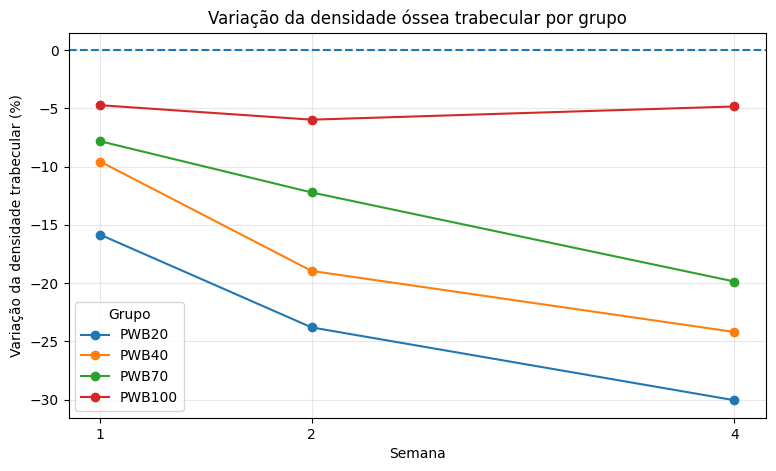

In [9]:
semanas = [1, 2, 4]
colunas_mudanca = [
    "trab_change_1",
    "trab_change_2",
    "trab_change_4"
]

plt.figure(figsize=(9, 5))

for grupo in ["PWB20", "PWB40", "PWB70", "PWB100"]:
    medias = [
        df.loc[df["PWB"] == grupo, coluna].mean()
        for coluna in colunas_mudanca
    ]

    plt.plot(semanas, medias, marker="o", label=grupo)

plt.axhline(0, linestyle="--")
plt.xlabel("Semana")
plt.ylabel("Variação da densidade trabecular (%)")
plt.title("Variação da densidade óssea trabecular por grupo")
plt.xticks(semanas)
plt.legend(title="Grupo")
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
for tecido in ["trab", "cort"]:
    for semana in [1, 2, 4]:
        inicial = df[f"{tecido}_BMD_0"]
        posterior = df[f"{tecido}_BMD_{semana}"]
        registrada = df[f"{tecido}_change_{semana}"]

        calculada = ((posterior - inicial) / inicial) * 100
        diferenca = (calculada - registrada).abs()

        verificacao = pd.DataFrame({
            "animal_id": df["animal_id"],
            "PWB": df["PWB"],
            "duracao": df["duracao"],
            "BMD_inicial": inicial,
            "BMD_posterior": posterior,
            "variacao_registrada": registrada,
            "variacao_calculada": calculada,
            "diferenca_absoluta": diferenca
        })

        suspeitos = verificacao[
            verificacao["diferenca_absoluta"] > 1
        ]

        if not suspeitos.empty:
            print(f"\nPossíveis divergências: {tecido}, semana {semana}")
            display(suspeitos.round(2))


Possíveis divergências: trab, semana 1


,animal_id,PWB,duracao,BMD_inicial,BMD_posterior,variacao_registrada,variacao_calculada,diferenca_absoluta
3,479660,PWB100,2wk,122.8,108.7,-14.5,-11.48,3.02
6,479663,PWB100,2wk,153.4,131.1,-11.5,-14.54,3.04
117,515406,PWB20,4wk,227.1,178.5,-14.1,-21.40,7.30



Possíveis divergências: trab, semana 2


,animal_id,PWB,duracao,BMD_inicial,BMD_posterior,variacao_registrada,variacao_calculada,diferenca_absoluta
3,479660,PWB100,2wk,122.8,100.9,-23.1,-17.83,5.27
6,479663,PWB100,2wk,153.4,117.9,-17.8,-23.14,5.34
117,515406,PWB20,4wk,227.1,139.6,-21.4,-38.53,17.13



Possíveis divergências: trab, semana 4


,animal_id,PWB,duracao,BMD_inicial,BMD_posterior,variacao_registrada,variacao_calculada,diferenca_absoluta
117,515406,PWB20,4wk,227.1,227.1,-38.5,0.0,38.5


In [13]:
print("Animais por grupo e duração:")
display(
    df.groupby(["PWB", "duracao"])
      .agg(
          n_animais=("animal_id", "nunique"),
          trab_semana1=("trab_BMD_1", "count"),
          trab_semana2=("trab_BMD_2", "count"),
          trab_semana4=("trab_BMD_4", "count")
      )
)

Animais por grupo e duração:


n_animais  trab_semana1  trab_semana2  trab_semana4
PWB    duracao                                                     
PWB100 1wk              7             7             0             0
       2wk             10            10            10             0
       4wk             13            13            13            13
PWB20  1wk              6             6             0             0
       2wk             12            12            12             0
       4wk             10            10            10            10
PWB40  1wk              6             6             0             0
       2wk             12            12            12             0
       4wk             12            12            12            12
PWB70  1wk             10            10             0             0
       2wk             11            11            11             0
       4wk             11            11            11            11

In [14]:
colunas = {
    "1wk": "trab_change_1",
    "2wk": "trab_change_2",
    "4wk": "trab_change_4"
}

for duracao, coluna in colunas.items():
    print(f"\nVariação da densidade trabecular — {duracao}")

    subset = df[df["duracao"] == duracao]

    resumo = (
        subset.groupby("PWB")[coluna]
        .agg(["count", "mean", "std", "median", "min", "max"])
        .round(2)
    )

    display(resumo)


Variação da densidade trabecular — 1wk


,count,mean,std,median,min,max
PWB,,,,,,
PWB100,7,-0.07,6.79,0.60,-9.6,8.1
PWB20,6,-18.13,9.12,-13.20,-31.5,-10.8
PWB40,6,-8.45,6.22,-5.85,-18.5,-3.4
PWB70,10,-12.31,9.62,-11.70,-27.0,0.1



Variação da densidade trabecular — 2wk


,count,mean,std,median,min,max
PWB,,,,,,
PWB100,10,-8.83,8.73,-6.6,-23.1,5.6
PWB20,12,-27.19,9.68,-30.2,-38.7,-10.1
PWB40,12,-20.82,9.07,-23.3,-36.4,-4.3
PWB70,11,-10.22,7.14,-8.6,-18.9,0.1



Variação da densidade trabecular — 4wk


,count,mean,std,median,min,max
PWB,,,,,,
PWB100,13,-4.83,12.18,-7.2,-21.8,26.7
PWB20,10,-30.06,9.36,-27.0,-48.7,-18.7
PWB40,12,-24.20,7.44,-24.2,-39.3,-11.2
PWB70,11,-19.86,8.45,-16.7,-36.9,-8.6


In [15]:
from scipy.stats import kruskal

colunas_por_duracao = {
    "1wk": "trab_change_1",
    "2wk": "trab_change_2",
    "4wk": "trab_change_4"
}

for duracao, coluna in colunas_por_duracao.items():
    subset = df[df["duracao"] == duracao]

    grupos = [
        subset.loc[subset["PWB"] == grupo, coluna].dropna()
        for grupo in ["PWB20", "PWB40", "PWB70", "PWB100"]
    ]

    estatistica, p_valor = kruskal(*grupos)

    print(f"\nDuração: {duracao}")
    print(f"Estatística H: {estatistica:.3f}")
    print(f"Valor-p: {p_valor:.5f}")


Duração: 1wk
Estatística H: 11.775
Valor-p: 0.00820

Duração: 2wk
Estatística H: 18.935
Valor-p: 0.00028

Duração: 4wk
Estatística H: 25.428
Valor-p: 0.00001


In [17]:
grupos_pwb = ["PWB20", "PWB40", "PWB70", "PWB100"]
colunas_por_duracao = {
    "1wk": "trab_change_1",
    "2wk": "trab_change_2",
    "4wk": "trab_change_4"
}

resultados = []

for duracao, coluna in colunas_por_duracao.items():
    subset = df[df["duracao"] == duracao]

    comparacoes = []

    for g1, g2 in combinations(grupos_pwb, 2):
        valores1 = subset.loc[subset["PWB"] == g1, coluna].dropna()
        valores2 = subset.loc[subset["PWB"] == g2, coluna].dropna()

        estatistica, p = mannwhitneyu(
            valores1, valores2, alternative="two-sided"
        )

        comparacoes.append({
            "duracao": duracao,
            "grupo_1": g1,
            "grupo_2": g2,
            "media_1": valores1.mean(),
            "media_2": valores2.mean(),
            "p_original": p
        })

    p_ajustados = multipletests(
        [c["p_original"] for c in comparacoes],
        method="holm"
    )[1]

    for comparacao, p_ajustado in zip(comparacoes, p_ajustados):
        comparacao["p_ajustado_holm"] = p_ajustado
        comparacao["significativo_05"] = p_ajustado < 0.05
        resultados.append(comparacao)

resultado_posthoc = pd.DataFrame(resultados)

display(
    resultado_posthoc.round(4)
    .sort_values(["duracao", "p_ajustado_holm"])
    .reset_index(drop=True)
)

,duracao,grupo_1,grupo_2,media_1,media_2,p_original,p_ajustado_holm,significativo_05
0,1wk,PWB20,PWB100,-18.1333,-0.0714,0.0012,0.0070,True
1,1wk,PWB70,PWB100,-12.3100,-0.0714,0.0146,0.0732,False
2,1wk,PWB20,PWB40,-18.1333,-8.4500,0.0931,0.2937,False
3,1wk,PWB40,PWB100,-8.4500,-0.0714,0.0734,0.2937,False
4,1wk,PWB20,PWB70,-18.1333,-12.3100,0.2635,0.5270,False
5,1wk,PWB40,PWB70,-8.4500,-12.3100,0.6354,0.6354,False
6,2wk,PWB20,PWB70,-27.1917,-10.2182,0.0008,0.0048,True
7,2wk,PWB20,PWB100,-27.1917,-8.8300,0.0017,0.0087,True
8,2wk,PWB40,PWB70,-20.8167,-10.2182,0.0106,0.0367,True
9,2wk,PWB40,PWB100,-20.8167,-8.8300,0.0092,0.0367,True


In [18]:
arquivos_enviados = files.upload()

print("Arquivos carregados:")
for nome in arquivos_enviados:
    print("-", nome)

Saving LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoGLOSSARY.xlsx to LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoGLOSSARY.xlsx
Saving LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoSUBMITTED.xlsx to LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoSUBMITTED.xlsx
Saving LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoTRANSFORMED.csv to LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoTRANSFORMED (1).csv
Arquivos carregados:
- LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoGLOSSARY.xlsx
- LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoSUBMITTED.xlsx
- LSDS-41_peripheral_quantitative_computed_tomography_pQCT_LSDS-41_pQCT_KoTRANSFORMED (1).csv


In [21]:
# Localizar os arquivos enviados
arquivos = list(Path("/content").glob("*"))

csv_path = next(
    p for p in arquivos
    if "KoTRANSFORMED" in p.name and p.suffix.lower() == ".csv"
)

submitted_path = next(
    p for p in arquivos
    if "KoSUBMITTED" in p.name and p.suffix.lower() == ".xlsx"
)

glossary_path = next(
    p for p in arquivos
    if "KoGLOSSARY" in p.name and p.suffix.lower() == ".xlsx"
)

# Nomes das colunas conforme o cabeçalho do CSV
colunas = [
    "animal_id", "PWB", "duracao",
    "trab_BMD_0", "trab_BMD_1", "trab_BMD_2", "trab_BMD_4",
    "trab_change_1", "trab_change_2", "trab_change_4",
    "cort_BMD_0", "cort_BMD_1", "cort_BMD_2", "cort_BMD_4",
    "cort_change_1", "cort_change_2", "cort_change_4"
]

df = pd.read_csv(csv_path, skiprows=2, header=None, names=colunas)

# Converter colunas numéricas
colunas_numericas = [
    c for c in df.columns
    if c not in ["PWB", "duracao"]
]

df[colunas_numericas] = df[colunas_numericas].apply(
    pd.to_numeric, errors="coerce"
)

df["animal_id"] = df["animal_id"].astype("Int64")

print("Dimensão:", df.shape)
display(df.head())

Dimensão: (120, 17)


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_1,trab_BMD_2,trab_BMD_4,trab_change_1,trab_change_2,trab_change_4,cort_BMD_0,cort_BMD_1,cort_BMD_2,cort_BMD_4,cort_change_1,cort_change_2,cort_change_4
0,475796,PWB100,4wk,181.7,165.6,162.6,168.7,-8.9,-10.5,-7.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,475803,PWB100,4wk,202.5,185.4,173.7,181.6,-8.4,-14.2,-10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,479659,PWB100,1wk,133.6,139.1,NaN,NaN,4.1,NaN,NaN,1270.3,1282.3,NaN,NaN,0.9,NaN,NaN
3,479660,PWB100,2wk,122.8,108.7,100.9,NaN,-14.5,-23.1,NaN,1303.5,1312.5,1327.3,NaN,0.7,1.8,NaN
4,479661,PWB20,2wk,141.8,127.0,113.1,NaN,-10.4,-20.2,NaN,1306.8,1321.4,1319.8,NaN,1.1,1.0,NaN


In [22]:
# Verificar se existem medidas posteriores à duração indicada
for semana in [2, 4]:
    coluna = f"trab_BMD_{semana}"

    inconsistencias = df[
        (df["duracao"] == "1wk") &
        (df[coluna].notna())
    ]

    print(
        f"Animais com duração de 1 semana e {coluna} preenchido:",
        len(inconsistencias)
    )

    display(
        inconsistencias[
            ["animal_id", "PWB", "duracao", coluna]
        ]
    )

Animais com duração de 1 semana e trab_BMD_2 preenchido: 0


,animal_id,PWB,duracao,trab_BMD_2


Animais com duração de 1 semana e trab_BMD_4 preenchido: 0


,animal_id,PWB,duracao,trab_BMD_4


In [23]:
for semana in [1, 2, 4]:
    bmd_inicial = df["trab_BMD_0"]
    bmd_final = df[f"trab_BMD_{semana}"]
    percentual_registrado = df[f"trab_change_{semana}"]

    percentual_calculado = (
        (bmd_final - bmd_inicial) / bmd_inicial
    ) * 100

    df[f"trab_change_{semana}_calculado"] = percentual_calculado

    df[f"trab_diferenca_{semana}"] = (
        percentual_registrado - percentual_calculado
    )

print("Cálculo concluído!")

Cálculo concluído!


In [24]:
for semana in [1, 2, 4]:
    coluna_diferenca = f"trab_diferenca_{semana}"

    divergencias = df[
        df[coluna_diferenca].abs() > 1
    ][[
        "animal_id", "PWB", "duracao",
        "trab_BMD_0", f"trab_BMD_{semana}",
        f"trab_change_{semana}",
        f"trab_change_{semana}_calculado",
        coluna_diferenca
    ]].copy()

    print(f"\nDivergências na semana {semana}: {len(divergencias)}")

    display(
        divergencias.sort_values(
            coluna_diferenca,
            key=abs,
            ascending=False
        )
    )


Divergências na semana 1: 3


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_1,trab_change_1,trab_change_1_calculado,trab_diferenca_1
117,515406,PWB20,4wk,227.1,178.5,-14.1,-21.400264,7.300264
6,479663,PWB100,2wk,153.4,131.1,-11.5,-14.537158,3.037158
3,479660,PWB100,2wk,122.8,108.7,-14.5,-11.482085,-3.017915



Divergências na semana 2: 3


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_2,trab_change_2,trab_change_2_calculado,trab_diferenca_2
117,515406,PWB20,4wk,227.1,139.6,-21.4,-38.529282,17.129282
6,479663,PWB100,2wk,153.4,117.9,-17.8,-23.142112,5.342112
3,479660,PWB100,2wk,122.8,100.9,-23.1,-17.833876,-5.266124



Divergências na semana 4: 1


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_4,trab_change_4,trab_change_4_calculado,trab_diferenca_4
117,515406,PWB20,4wk,227.1,227.1,-38.5,0.0,-38.5


In [25]:
ids_verificar = ["515406", "479663", "479660"]

xls = pd.ExcelFile(submitted_path)

for aba in xls.sheet_names:
    dados = pd.read_excel(
        submitted_path,
        sheet_name=aba,
        header=None,
        dtype=str
    )

    # Procurar os IDs em qualquer coluna da aba
    mascara = dados.apply(
        lambda coluna: coluna.str.contains(
            "|".join(ids_verificar),
            na=False,
            regex=True
        )
    ).any(axis=1)

    encontrados = dados[mascara]

    if not encontrados.empty:
        print(f"\nAba: {aba}")
        display(encontrados)


Aba: mCT, 3pt bend, pQCT


,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
133,515406,515406_Femur,PWB20,4wk,483.4,Femur,37.38,22.4811,1.859,0.0827,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
273,515406,515406_Tibia,PWB20,4wk,483.4,Tibia,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
original = pd.read_excel(
    submitted_path,
    sheet_name="mCT, 3pt bend, pQCT",
    header=None
)

# Mostrar as primeiras linhas, onde podem estar os cabeçalhos
display(original.iloc[:8, :20])

# Mostrar as linhas do animal 515406
linhas_515406 = original[
    original.iloc[:, 0].astype(str).str.strip() == "515406"
]

display(linhas_515406)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,NaN,NaN,NaN,NaN,BW,NaN,Fem Length,Femoral Trabecular Bone (mCT),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Femoral Midshaft Cortical Bone (mCT),NaN,NaN,NaN
1,Animal ID,ALSDA Name,PWB,Duration,Final Body weight [g],Tissue,Fem.Length [mm],TV [mm^3],BV [mm^3],BV/TV,Conn-Dens. [1/mm^3],SMI,Tb.N [1/mm],Tb.Th [mm],Tb.Sp [mm],BMD [mg/ccm],Cort.Th [mm],Cort.TMD [mg HA/ccm],pMOI[mm^4],Imax[mm^4]
2,479659,479659_Femur,PWB100,1wk,424.6,Femur,38.34,15.2574,3.7809,0.2478,55.7761,1.3106,2.3148,0.1086,0.4519,253.1274,0.7235,1128.312,14.46813,8.80459
3,479662,479662_Femur,PWB20,1wk,362.4,Femur,38.1,12.8185,0.8919,0.0696,13.6522,2.8273,1.6977,0.0726,0.6004,95.3453,0.6086,1088.9337,12.0387,7.58852
4,479664,479664_Femur,PWB40,1wk,371.1,Femur,37.86,16.1859,2.733,0.1689,42.8768,2.0626,1.9709,0.0911,0.5211,210.0797,0.5731,1082.8479,15.90857,10.18019
5,479665,479665_Femur,PWB70,1wk,370.5,Femur,38.34,14.801,1.6272,0.1099,21.7891,2.2342,1.3054,0.0908,0.7771,143.0469,0.7661,1129.0281,17.33907,10.78103
6,479666,479666_Femur,PWB20,1wk,382,Femur,38.46,15.5337,0.9243,0.0595,9.3668,2.7723,1.1219,0.0801,0.9063,63.4846,0.6333,1093.9454,15.35721,10.50786
7,479668,479668_Femur,PWB40,1wk,341,Femur,37.74,13.806,2.3405,0.1695,39.6204,1.7207,1.747,0.0985,0.6259,203.8149,0.6994,1135.8297,11.58147,7.19161


,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
133,515406,515406_Femur,PWB20,4wk,483.4,Femur,37.38,22.4811,1.859,0.0827,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
273,515406,515406_Tibia,PWB20,4wk,483.4,Tibia,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# Procurar nomes de colunas ou células que mencionem pQCT e BMD
for i in range(min(10, len(original))):
    linha = original.iloc[i].fillna("").astype(str)

    correspondencias = linha[
        linha.str.contains(
            r"pQCT|BMD|trab|cort|change|density",
            case=False,
            regex=True
        )
    ]

    if not correspondencias.empty:
        print(f"\nLinha {i}:")
        display(correspondencias.to_frame("conteúdo"))


Linha 0:


,conteúdo
7,Femoral Trabecular Bone (mCT)
16,Femoral Midshaft Cortical Bone (mCT)
34,Trab BMD [mg/ccm] pqct
38,% Trab BMD Change from Baseline
41,Cort BMD [mg/ccm]
45,% Cort BMD Change



Linha 1:


,conteúdo
15,BMD [mg/ccm]
16,Cort.Th [mm]
17,Cort.TMD [mg HA/ccm]


In [28]:
for i in range(8):
    print(f"\n--- Linha {i} ---")
    for j, valor in enumerate(original.iloc[i]):
        if pd.notna(valor) and str(valor).strip():
            print(f"Coluna {j}: {valor}")


--- Linha 0 ---
Coluna 4: BW
Coluna 6: Fem Length
Coluna 7: Femoral Trabecular Bone (mCT)
Coluna 16: Femoral Midshaft Cortical Bone (mCT)
Coluna 24: 3 Point Bending of Midshaft (3pt bend)
Coluna 34: Trab BMD [mg/ccm] pqct
Coluna 38: % Trab BMD Change from Baseline
Coluna 41: Cort BMD [mg/ccm]
Coluna 45: % Cort BMD Change

--- Linha 1 ---
Coluna 0: Animal ID
Coluna 1: ALSDA Name
Coluna 2: PWB
Coluna 3: Duration
Coluna 4: Final Body weight [g]
Coluna 5: Tissue
Coluna 6: Fem.Length [mm]
Coluna 7: TV [mm^3]
Coluna 8: BV [mm^3]
Coluna 9: BV/TV
Coluna 10: Conn-Dens. [1/mm^3]
Coluna 11: SMI
Coluna 12: Tb.N [1/mm]
Coluna 13: Tb.Th [mm]
Coluna 14: Tb.Sp [mm]
Coluna 15: BMD [mg/ccm]
Coluna 16: Cort.Th [mm]
Coluna 17: Cort.TMD [mg HA/ccm]
Coluna 18: pMOI[mm^4]
Coluna 19: Imax[mm^4]
Coluna 20: Imin[mm^4]
Coluna 21: BArea[mm^2]
Coluna 22: TArea[mm^2]
Coluna 23:   BA/TA[1]
Coluna 24: Stiffness (N/mm)
Coluna 25: MaxLoad (N)
Coluna 26: FailLoad (N)
Coluna 27: Bending Stiffness [N*mm^2]
Coluna 28: Max

In [29]:
glossary_path = next(
    p for p in Path("/content").glob("*")
    if "KoGLOSSARY" in p.name and p.suffix.lower() == ".xlsx"
)

xls_glossary = pd.ExcelFile(glossary_path)

print("Abas:", xls_glossary.sheet_names)

for aba in xls_glossary.sheet_names:
    print(f"\n--- {aba} ---")
    dados = pd.read_excel(glossary_path, sheet_name=aba)
    display(dados.head(20))

Abas: ['Read Me', 'Glossary']

--- Read Me ---


,READ ME for DATA REPOSITORY NNX16AL36G,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,All animals enrolled in this study are Wistar ...,NaN,NaN,NaN
2,This repository excludes all bone related outc...,NaN,NaN,NaN
3,Data that has not been published yet is noted ...,NaN,NaN,NaN
4,Missing values are reported as NA (not available),NaN,NaN,NaN
5,"For clarity purposes, animals are separated by...",NaN,NaN,NaN
6,All indications are made in days (for example ...,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN
8,Title,Description,Total Duration,NaN
9,Jove,1 week of HLS immediately followed by 1 week p...,14 days,NaN



--- Glossary ---


,Acronym,Meaning,Units
0,%MyHC1,% of myofiber type 1 (slow twitch),%
1,14 days - R+14 days,14 days of PWB followed by 14 days of reloadin...,NaN
2,Biceps,Biceps Brachii,grams
3,Blood glucose,Blood Glucose obtained from the tail vein,mg/dL
4,BP,Blood Pressure obtained from the tail,mmHg
5,BW,Body Weight,Grams
6,CFI,Cumulative Food Intake,Grams
7,CSA,All Myofiber cross section area,um2
8,DF AUC,Dorsi Flexion Area Under Curve,mN.sec
9,EDL,Extensor Digitorum Longus,grams


In [30]:
glossary = pd.read_excel(
    glossary_path,
    sheet_name="Glossary"
)

termos = r"BMD|pQCT|trab|cort|bone|density|change|PWB"

encontrados = glossary[
    glossary.astype(str).apply(
        lambda coluna: coluna.str.contains(
            termos, case=False, regex=True, na=False
        )
    ).any(axis=1)
]

display(encontrados)

,Acronym,Meaning,Units
1,14 days - R+14 days,14 days of PWB followed by 14 days of reloadin...,NaN
10,FPGF %,Front Paw Grip Force (% change from baseline),%
14,HLS-PWB40,7 days at HLS immediately followed by 7 days a...,NaN
20,Plasma Cort,Plasma Corticosterone,ng/mL
21,PWB,Partial Weight Bearing,NaN
23,RPGF %,Rear Paw Grip Force (% change from baseline),%
32,BV,Bone volume,mm^3
33,BV/TV,Bone volume per total volume,mm^3/mm^3
34,Conn-Dens.,Connectivity Density,1/mm^3
36,Tb.N,Trabecular number,1/mm


In [31]:
readme = pd.read_excel(
    glossary_path,
    sheet_name="Read Me",
    header=None
)

for i, linha in readme.iterrows():
    texto = " | ".join(
        str(v) for v in linha if pd.notna(v)
    )

    if texto.strip():
        print(f"Linha {i}: {texto}")

Linha 0: READ ME for DATA REPOSITORY NNX16AL36G
Linha 2: All animals enrolled in this study are Wistar Rats who start baseline at 14 weeks of age, they are received at 13 weeks of age to allow for acclimation
Linha 3: This repository excludes all bone related outcomes
Linha 4: Data that has not been published yet is noted in red
Linha 5: Missing values are reported as NA (not available)
Linha 6: For clarity purposes, animals are separated by experiments, including longitudinal and terminal measurements, a quick guide follows
Linha 7: All indications are made in days (for example BW7 means BW at day 7), day 0 always refers to pre-suspension baseline.
Linha 9: Title | Description | Total Duration
Linha 10: Jove | 1 week of HLS immediately followed by 1 week pf PWB40 | 14 days
Linha 11: RSV | daily RSV supplementation at 150 mg/kg/day | 14 days
Linha 12: Reloading | 2 weeks of PWB followed by 2 weeks at PWB100 (+/- RSV) | 28 days (R+14)
Linha 13: Females | 2 weeks of PWB | 14 days
Linha 1

In [32]:
# Listar todas as abas do arquivo SUBMITTED
xls_submitted = pd.ExcelFile(submitted_path)

for i, aba in enumerate(xls_submitted.sheet_names):
    print(i, "-", aba)

0 - Read Me
1 - Glossary
2 - mCT, 3pt bend, pQCT
3 - histomorph


In [33]:
for aba in xls_submitted.sheet_names:
    dados = pd.read_excel(
        submitted_path,
        sheet_name=aba,
        header=None,
        nrows=8
    )

    texto = dados.fillna("").astype(str).to_string().lower()

    if "qpct" in texto or "trab bmd" in texto or "cort bmd" in texto:
        print(f"\nPossível aba relevante: {aba}")
        display(dados)


Possível aba relevante: mCT, 3pt bend, pQCT


,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
0,NaN,NaN,NaN,NaN,BW,NaN,Fem Length,Femoral Trabecular Bone (mCT),NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Animal ID,ALSDA Name,PWB,Duration,Final Body weight [g],Tissue,Fem.Length [mm],TV [mm^3],BV [mm^3],BV/TV,...,Oc.S/BS,MS/BS,MAR,BFR/BS,Ps.MS/BS,Ps.MAR,Ps.BFR/BS,Ec.MS/BS,Ec.MAR,Ec.BFR/BS
2,479659,479659_Femur,PWB100,1wk,424.6,Femur,38.34,15.2574,3.7809,0.2478,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,479662,479662_Femur,PWB20,1wk,362.4,Femur,38.1,12.8185,0.8919,0.0696,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,479664,479664_Femur,PWB40,1wk,371.1,Femur,37.86,16.1859,2.733,0.1689,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,479665,479665_Femur,PWB70,1wk,370.5,Femur,38.34,14.801,1.6272,0.1099,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,479666,479666_Femur,PWB20,1wk,382,Femur,38.46,15.5337,0.9243,0.0595,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,479668,479668_Femur,PWB40,1wk,341,Femur,37.74,13.806,2.3405,0.1695,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:

# Ler a planilha completa, preservando as duas linhas de cabeçalho
original = pd.read_excel(
    submitted_path,
    sheet_name="mCT, 3pt bend, pQCT",
    header=None
)

# Procurar os animais na coluna Animal ID
ids_investigar = [515406, 479663, 479660]

ids_planilha = pd.to_numeric(original.iloc[:, 0], errors="coerce")

for animal_id in ids_investigar:
    linhas = original[ids_planilha == animal_id]

    print(f"\n{'='*60}")
    print(f"Animal: {animal_id} | Linhas encontradas: {len(linhas)}")

    if len(linhas) > 0:
        display(linhas.T)
    else:
        print("Animal não encontrado nessa planilha.")



Animal: 515406 | Linhas encontradas: 2


,133,273
0,515406,515406
1,515406_Femur,515406_Tibia
2,PWB20,PWB20
3,4wk,4wk
4,483.4,483.4
...,...,...
57,NaN,NaN
58,NaN,NaN
59,NaN,NaN
60,NaN,NaN



Animal: 479663 | Linhas encontradas: 0
Animal não encontrado nessa planilha.

Animal: 479660 | Linhas encontradas: 0
Animal não encontrado nessa planilha.


In [35]:

# Mostrar os nomes das colunas e os valores da linha da tíbia
linha_tibia = original[
    (pd.to_numeric(original.iloc[:, 0], errors="coerce") == 515406)
    & (original.iloc[:, 1].astype(str).str.contains("Tibia", case=False, na=False))
]

if not linha_tibia.empty:
    for coluna in range(original.shape[1]):
        nome = original.iloc[1, coluna]
        valor = linha_tibia.iloc[0, coluna]
        if pd.notna(nome) or pd.notna(valor):
            print(f"Coluna {coluna} | {nome}: {valor}")
else:
    print("Registro da tíbia não encontrado.")


Coluna 0 | Animal ID: 515406
Coluna 1 | ALSDA Name: 515406_Tibia
Coluna 2 | PWB: PWB20
Coluna 3 | Duration: 4wk
Coluna 4 | Final Body weight [g]: 483.4
Coluna 5 | Tissue: Tibia
Coluna 6 | Fem.Length [mm]: nan
Coluna 7 | TV [mm^3]: nan
Coluna 8 | BV [mm^3]: nan
Coluna 9 | BV/TV: nan
Coluna 10 | Conn-Dens. [1/mm^3]: nan
Coluna 11 | SMI: nan
Coluna 12 | Tb.N [1/mm]: nan
Coluna 13 | Tb.Th [mm]: nan
Coluna 14 | Tb.Sp [mm]: nan
Coluna 15 | BMD [mg/ccm]: nan
Coluna 16 | Cort.Th [mm]: nan
Coluna 17 | Cort.TMD [mg HA/ccm]: nan
Coluna 18 | pMOI[mm^4]: nan
Coluna 19 | Imax[mm^4]: nan
Coluna 20 | Imin[mm^4]: nan
Coluna 21 | BArea[mm^2]: nan
Coluna 22 | TArea[mm^2]: nan
Coluna 23 |   BA/TA[1]: nan
Coluna 24 | Stiffness (N/mm): nan
Coluna 25 | MaxLoad (N): nan
Coluna 26 | FailLoad (N): nan
Coluna 27 | Bending Stiffness [N*mm^2]: nan
Coluna 28 | Max Moment [N*mm]: nan
Coluna 29 | Fail Moment [N*mm]: nan
Coluna 30 | Imax[mm^4]: nan
Coluna 31 | Imin[mm^4]: nan
Coluna 32 | Estimated modulus [MPa]: nan
C

In [36]:

animal_id = 515406

print("CSV TRANSFORMADO")
display(
    df.loc[
        df["animal_id"] == animal_id,
        [
            "animal_id", "PWB", "duracao",
            "trab_BMD_0", "trab_BMD_1",
            "trab_BMD_2", "trab_BMD_4",
            "trab_change_1", "trab_change_2",
            "trab_change_4"
        ]
    ]
)

print("\nPLANILHA SUBMITTED — CABEÇALHO E VALORES DA TÍBIA")
linha_tibia = original[
    (pd.to_numeric(original.iloc[:, 0], errors="coerce") == animal_id)
    & (original.iloc[:, 1].astype(str).str.contains("Tibia", case=False, na=False))
]

for coluna in range(34, 48):
    print(
        f"Coluna {coluna}: "
        f"cabeçalho = {original.iloc[1, coluna]!r} | "
        f"valor = {linha_tibia.iloc[0, coluna]!r}"
    )


CSV TRANSFORMADO


,animal_id,PWB,duracao,trab_BMD_0,trab_BMD_1,trab_BMD_2,trab_BMD_4,trab_change_1,trab_change_2,trab_change_4
117,515406,PWB20,4wk,227.1,178.5,139.6,227.1,-14.1,-21.4,-38.5



PLANILHA SUBMITTED — CABEÇALHO E VALORES DA TÍBIA
Coluna 34: cabeçalho = '0 week' | valor = 227.1
Coluna 35: cabeçalho = '1 week' | valor = 178.5000000018
Coluna 36: cabeçalho = '2 week' | valor = 139.5999998967
Coluna 37: cabeçalho = '4 week' | valor = 227.1
Coluna 38: cabeçalho = '1 week' | valor = -14.1347424
Coluna 39: cabeçalho = '2 week' | valor = -21.4002642
Coluna 40: cabeçalho = '4 week' | valor = -38.5292823
Coluna 41: cabeçalho = '0 week' | valor = 0
Coluna 42: cabeçalho = '1 week' | valor = 0
Coluna 43: cabeçalho = '2 week' | valor = 0
Coluna 44: cabeçalho = '4 week' | valor = 0
Coluna 45: cabeçalho = '1 week' | valor = 0
Coluna 46: cabeçalho = '2 week' | valor = 0
Coluna 47: cabeçalho = '4 week' | valor = 0


In [37]:

# Procurar termos relacionados à variação de BMD no glossário
glossario = pd.read_excel(glossary_path, sheet_name="Glossary", header=None)

termos = ["trab bmd", "change", "percent", "pQCT", "bone mineral density"]

for termo in termos:
    encontrados = glossario[
        glossario.astype(str).apply(
            lambda coluna: coluna.str.contains(
                termo, case=False, na=False
            )
        ).any(axis=1)
    ]

    print(f"\n--- Busca: {termo} ---")
    if encontrados.empty:
        print("Nenhuma correspondência encontrada no glossário.")
    else:
        display(encontrados)



--- Busca: trab bmd ---


,0,1,2
49,Trab BMD,Trabecular bone mineral density,mg/cm^3



--- Busca: change ---


,0,1,2
11,FPGF %,Front Paw Grip Force (% change from baseline),%
24,RPGF %,Rear Paw Grip Force (% change from baseline),%



--- Busca: percent ---
Nenhuma correspondência encontrada no glossário.

--- Busca: pQCT ---
Nenhuma correspondência encontrada no glossário.

--- Busca: bone mineral density ---


,0,1,2
40,BMD,Bone mineral density,mg/cm^3
49,Trab BMD,Trabecular bone mineral density,mg/cm^3
50,Cort BMD,Cortical bone mineral density,mg/cm^3


In [38]:

# Mostrar todas as abas e dimensões do arquivo SUBMITTED
xls_submitted = pd.ExcelFile(submitted_path)

for aba in xls_submitted.sheet_names:
    dados = pd.read_excel(
        submitted_path,
        sheet_name=aba,
        header=None
    )

    print(
        f"Aba: {aba} | "
        f"Dimensão: {dados.shape}"
    )
    print("Primeiras linhas:")
    display(dados.head(3))


Aba: Read Me | Dimensão: (39, 4)
Primeiras linhas:


,0,1,2,3
0,READ ME for DATA REPOSITORY NNX16AL36G,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,All animals enrolled in this study are Wistar ...,NaN,NaN,NaN


Aba: Glossary | Dimensão: (51, 3)
Primeiras linhas:


,0,1,2
0,Acronym,Meaning,Units
1,%MyHC1,% of myofiber type 1 (slow twitch),%
2,14 days - R+14 days,14 days of PWB followed by 14 days of reloadin...,NaN


Aba: mCT, 3pt bend, pQCT | Dimensão: (284, 62)
Primeiras linhas:


,0,1,2,3,4,5,6,7,8,9,...,52,53,54,55,56,57,58,59,60,61
0,NaN,NaN,NaN,NaN,BW,NaN,Fem Length,Femoral Trabecular Bone (mCT),NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Animal ID,ALSDA Name,PWB,Duration,Final Body weight [g],Tissue,Fem.Length [mm],TV [mm^3],BV [mm^3],BV/TV,...,Oc.S/BS,MS/BS,MAR,BFR/BS,Ps.MS/BS,Ps.MAR,Ps.BFR/BS,Ec.MS/BS,Ec.MAR,Ec.BFR/BS
2,479659,479659_Femur,PWB100,1wk,424.6,Femur,38.34,15.2574,3.7809,0.2478,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Aba: histomorph | Dimensão: (60, 14)
Primeiras linhas:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,Sample,PWB,Duration,Ob.S/BS,Oc.S/BS,MS/BS,MAR,BFR/BS,Ps.MS/BS,Ps.MAR,Ps.BFR/BS,Ec.MS/BS,Ec.MAR,Ec.BFR/BS
1,491052,0.4G,2wk,2.28,7.74,1.95,0.59,0.0115,17.2,1.24,0.213,12.7,1.72,0.218
2,491053,1G,2wk,5.52,4.12,8.44,1.98,0.167,38.7,1.75,0.678,43.1,3.58,1.54
